<a href="https://colab.research.google.com/github/hyo-yeon-lee/MCNB-Probability-and-Statistics/blob/main/Lecture04_ANOVA_p_hacking_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Exercise 1: ANOVA

Below is code for running a 1-way ANOVA to test which university has the highest number of nights out, as in the example discussed during the lecture.

We will use ```seaborn``` to make a violin plot (as discussed in the programming course yesterday), and functions from the ```statsmodels``` package to run ANOVA and Tuckey HSD post-hoc tests.

You do not need to do anything in this code cell, but you will need to understand the steps in order to complete the next assignment. Here are some explanations.

1. The data is just random stuff I came up with. We have n_nights_out for our three universities.
2. Both ```seaborn``` and ```statsmodels``` work easily with ```pandas``` dataframes (as we saw in the programming course in the case of seaborn). Therefore, we create a dataframe with two columns: ```"University"``` and ```"NightsOut"``` (note that we shouldn't use spaces in these column names), where we associate each datapoint of the dependent variable (i.e., nights out for a particular student) with the corresponding dependent variable group (i.e., which uni the student comes from).
3. We use ```seaborn``` to make a violin plot. This is easy, thanks to the ```pandas``` datadframe we made. *Note: The ```stripplot``` line is there to show the individual datapoints. on top of the violins.*
4. We use ```statsmodels``` to run the ANOVA. A few notes:
    - Statsmodels, like many libraries, implements ANOVA in the framework of linear regression, which is why there is a ```.fit()``` in the code. *We have not covered this link between ANOVA and regression, so you do not need to understand this right now. For now, you can just take for granted that these two lines run an ANOVA*.
    - Let's unpack the ```'NightsOut ~ C(University)'``` line. This means that ```'NightsOut'``` in the ```pandas``` df is the independent variable, which we want to explain in terms of the independent variable (or "factor") ```'University'```. Because this is a *categorical* variable, we use ```C('University')```.
        - You could other factors by using ```'DepVar ~ C(Factor1) * C(Factor2) * ... * C(FactorN)'```
    - ```print(anova_results)``` gives us a table with quite a lot of info, as we saw in class. Make sure you understand it.
5. We run Tuckey's HSD post-hoc test, also from ```statsmodels```.
    - The ```endog=``` argument stands for "endogenous variable".
    - ```print(tukey_results)``` gives us a table with quite a lot of info, as we saw in class. Make sure you understand it.

The idea of this code cell is to give you code that you can re-use later for making violin plots and running 1-way ANOVAs. Make sure you understand what is going on.

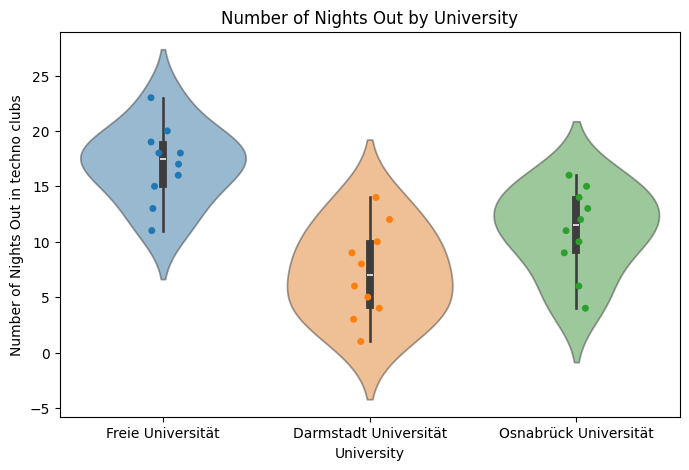

                 df      sum_sq     mean_sq          F    PR(>F)
C(University)   2.0  488.266667  244.133333  16.662285  0.000019
Residual       27.0  395.600000   14.651852        NaN       NaN
                Multiple Comparison of Means - Tukey HSD, FWER=0.05                
        group1                group2        meandiff p-adj   lower    upper  reject
-----------------------------------------------------------------------------------
Darmstadt Universität     Freie Universität      9.8    0.0   5.5557 14.0443   True
Darmstadt Universität Osnabrück Universität      3.8 0.0858  -0.4443  8.0443  False
    Freie Universität Osnabrück Universität     -6.0 0.0044 -10.2443 -1.7557   True
-----------------------------------------------------------------------------------


In [26]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data: number of nights out in a techno club for students from three universities
freie_universitat = np.array([18, 17, 19, 15, 18, 20, 16, 13, 23, 11])
darmstadt_universitat = np.array([3, 4, 8, 5, 14, 9, 6, 1, 10, 12])
osnabruck_universitat = np.array([14, 15, 16, 13, 11, 4, 6, 9, 10, 12])

# 2. Prepare data in a pandas dataframe for statsmodels and seaborn
data = np.concatenate([freie_universitat, darmstadt_universitat, osnabruck_universitat])
labels = ['Freie Universität'] * len(freie_universitat) + \
         ['Darmstadt Universität'] * len(darmstadt_universitat) + \
         ['Osnabrück Universität'] * len(osnabruck_universitat)
df = pd.DataFrame({"University": labels, "NightsOut": data})

# 3. Plotting with violinplot to show points and means
plt.figure(figsize=(8, 5))
sns.violinplot(x="University", y="NightsOut", data=df, hue="University", split=False, alpha=0.5)  # Background distribution with different colors
sns.stripplot(x="University", y="NightsOut", data=df, hue="University", jitter=True)  # Jittered points
plt.ylabel('Number of Nights Out in techno clubs')
plt.title('Number of Nights Out by University')
plt.show()

# 4. Perform one-way ANOVA using statsmodels
model = ols('NightsOut ~ C(University)', data=df).fit()
anova_results = sm.stats.anova_lm(model, typ=1)
print(anova_results)

# 5. Conduct Tukey's HSD post-hoc test
tukey_results = pairwise_tukeyhsd(endog=df['NightsOut'], groups=df['University'], alpha=0.05)
print(tukey_results)
plt.close()

Now, please come up with a different invented dataset, analogous to my invented dataset of Universities and NightsOut, plot your invented data and run a 1-way ANOVA. Here are some requirements:

1. Use five groups.
2. Make sure there is a significant result in ANOVA and that Tuckey HSD shows that three groups have similar mean while one is unusually large and another one unusually low.  

We can get inspired/re-use the code from the previous cell of course.

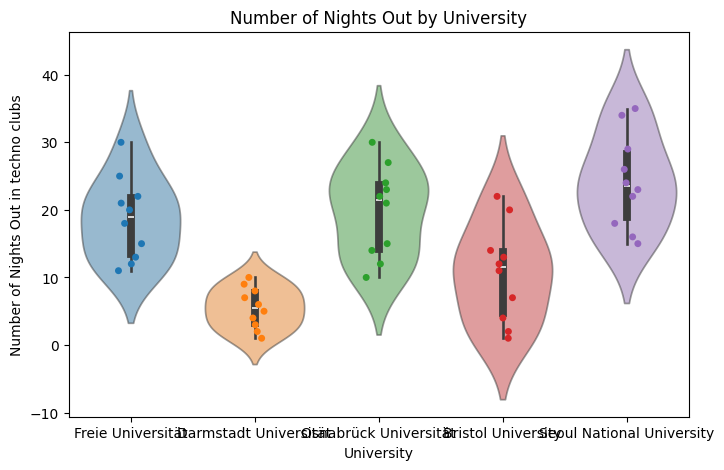

                 df   sum_sq     mean_sq          F        PR(>F)
C(University)   4.0  2280.92  570.230000  14.934437  7.689093e-08
Residual       45.0  1718.20   38.182222        NaN           NaN
                  Multiple Comparison of Means - Tukey HSD, FWER=0.05                  
        group1                  group2          meandiff p-adj   lower    upper  reject
---------------------------------------------------------------------------------------
   Bristol University     Darmstadt Universität     -5.1 0.3611 -12.9521  2.7521  False
   Bristol University         Freie Universität      8.1 0.0402   0.2479 15.9521   True
   Bristol University     Osnabrück Universität      9.2 0.0143   1.3479 17.0521   True
   Bristol University Seoul National University     13.6 0.0001   5.7479 21.4521   True
Darmstadt Universität         Freie Universität     13.2 0.0002   5.3479 21.0521   True
Darmstadt Universität     Osnabrück Universität     14.3    0.0   6.4479 22.1521   True
Darmstadt 

In [27]:
# Replace this line with your code
import numpy as np

freie_universitat_2 = np.random.choice(np.arange(1, 31), size=10, replace=False)
darmstadt_universitat_2 = np.random.choice(np.arange(1, 11), size=10, replace=False)
osnabruck_universitat_2 = np.random.choice(np.arange(10, 31), size=10, replace=False)
bristol_university = np.random.choice(np.arange(1, 23), size=10, replace=False)
snu = np.random.choice(np.arange(15, 37), size=10, replace=False)

data2 = np.concatenate([freie_universitat_2, darmstadt_universitat_2, osnabruck_universitat_2, bristol_university, snu])
labels_2 = ['Freie Universität'] * len(freie_universitat_2) + \
         ['Darmstadt Universität'] * len(darmstadt_universitat_2) + \
         ['Osnabrück Universität'] * len(osnabruck_universitat_2) + \
         ['Bristol University'] * len(bristol_university) + \
         ['Seoul National University'] * len(snu)
df = pd.DataFrame({"University": labels_2, "NightsOut": data2})

plt.figure(figsize=(8, 5))
sns.violinplot(x="University", y="NightsOut", data=df, hue="University", split=False, alpha=0.5)  # Background distribution with different colors
sns.stripplot(x="University", y="NightsOut", data=df, hue="University", jitter=True)  # Jittered points
plt.ylabel('Number of Nights Out in techno clubs')
plt.title('Number of Nights Out by University')
plt.show()

model = ols('NightsOut ~ C(University)', data=df).fit()
anova_results = sm.stats.anova_lm(model, typ=1)
print(anova_results)

tukey_results = pairwise_tukeyhsd(endog=df['NightsOut'], groups=df['University'], alpha=0.05)
print(tukey_results)
plt.close()





Finally, here is the code I used for my 2-way ANOVA example where the dependent variable is number of nights out, and the two factors are the University and students/professors.

You have two jobs:
1. Write the part where the ANOVA happens. The rest of the code is not considered required knowledge for the course. If you want, you can try and understand it of course!
2. Understand the outputs of the code.
    - Is there a main effect? What does that mean?
    - Is there an interaction? What does that mean?
    - What does Tuckey's post-hoc test tell us about what is significantly different from what?

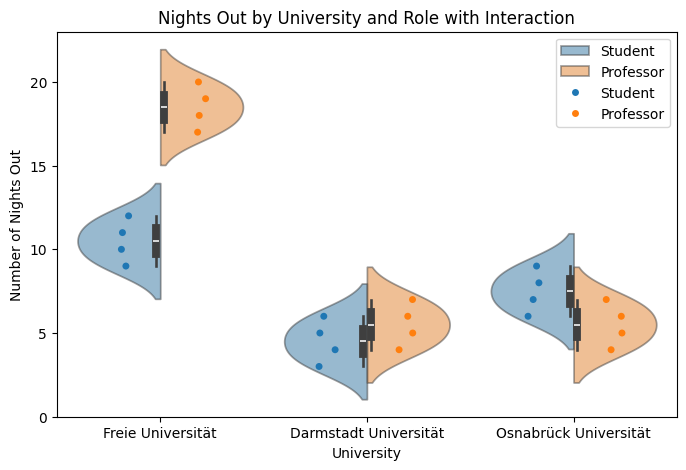

                   sum_sq    df          F    PR(>F)
C(University)  417.333333   2.0  26.083333  0.000002
Residual       168.000000  21.0        NaN       NaN
ANOVA Table:
                   sum_sq    df          F    PR(>F)
C(University)  417.333333   2.0  26.083333  0.000002
Residual       168.000000  21.0        NaN       NaN

Tukey's HSD Test:
                          Multiple Comparison of Means - Tukey HSD, FWER=0.05                           
             group1                          group2             meandiff p-adj   lower    upper   reject
--------------------------------------------------------------------------------------------------------
Darmstadt Universität_Professor   Darmstadt Universität_Student     -1.0 0.8769  -3.9011   1.9011  False
Darmstadt Universität_Professor     Freie Universität_Professor     13.0    0.0  10.0989  15.9011   True
Darmstadt Universität_Professor       Freie Universität_Student      5.0 0.0004   2.0989   7.9011   True
Darmstadt Universitä

In [29]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Create updated hypothetical data with interaction
data = {
    'NightsOut': [
        10, 11, 12, 9,   # Freie Universität (Students)
        18, 17, 19, 20,  # Freie Universität (Professors)
        4, 5, 3, 6,      # Darmstadt Universität (Students)
        6, 7, 5, 4,      # Darmstadt Universität (Professors)
        8, 9, 7, 6,      # Osnabrück Universität (Students)
        6, 4, 5, 7   # Osnabrück Universität (Professors)
    ],
    'University': [
        'Freie Universität'] * 4 + ['Freie Universität'] * 4 + \
        ['Darmstadt Universität'] * 4 + ['Darmstadt Universität'] * 4 + \
        ['Osnabrück Universität'] * 4 + ['Osnabrück Universität'] * 4,
    'Role': [
        'Student', 'Student', 'Student', 'Student',
        'Professor', 'Professor', 'Professor', 'Professor',
        'Student', 'Student', 'Student', 'Student',
        'Professor', 'Professor', 'Professor', 'Professor',
        'Student', 'Student', 'Student', 'Student',
        'Professor', 'Professor', 'Professor', 'Professor'
    ]
}

# Create a DataFrame
df = pd.DataFrame(data)

# Visualize the data
plt.figure(figsize=(8, 5))
sns.violinplot(x='University', y='NightsOut', hue='Role', data=df, split=True, alpha=0.5)
sns.stripplot(x="University", y="NightsOut", data=df, hue="Role", jitter=True, dodge=True)
plt.title('Nights Out by University and Role with Interaction')
plt.xlabel('University')
plt.ylabel('Number of Nights Out')
plt.legend(loc='upper right')
plt.show()

# Perform 2-way ANOVA
# Replace this line with your code
model = ols('NightsOut ~ C(University)', data=df).fit()
anova_results = sm.stats.anova_lm(model, typ=2)
print(anova_results)

# Display the ANOVA table
print("ANOVA Table:")
print(anova_results)

# Perform Tukey's HSD post-hoc test
tukey = pairwise_tukeyhsd(df['NightsOut'], df['University'] + "_" + df['Role'])
print("\nTukey's HSD Test:")
print(tukey)

#Exercise 2: Why we need to correct for multiple comparisons

Based on the math we covered in class, make a plot showing the probability of getting at least one false positive (Type I error) as we conduct more and more tests in a case where there is in fact no effect. In more detail:

0. To get started, just print the result for 10 tests. You should get about 0.4.

Then, make the plot.
1. x-axis should represent increasing number of tests.
2. y-axis should be p(at least one false positive) for the corresponding number of tests.

10 tests:  0.4012630607616213


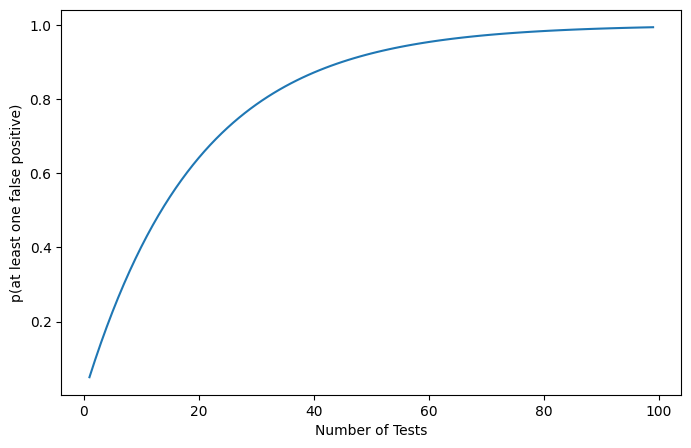

In [45]:
# Replace this line with your code

alpha = 0.05
print("10 tests: ", 1-(1-alpha)**10)

x = np.arange(1, 100)
y = 1-(1-alpha)**x

plt.figure(figsize=(8, 5))
plt.plot(x, y)
plt.xlabel('Number of Tests')
plt.ylabel('p(at least one false positive)')
plt.show()
plt.close()

#Exercise 3: Power analysis

Here is some code to run a power analysis for ttests, using functions from ```statsmodels``` again. Make sure you understand what this is doing. In particular:

1. What is the effect size here? And how do you chose it in practice?
2. What is alpha here?
3. What is power?

Make sure you can explain in a single sentence what this power analysis does.

Check that this result is in line with what you would find using this [online power calculator tool](https://www.statskingdom.com/sample_size_all.html).

You don't need to do anything in terms of code.

In [43]:
from statsmodels.stats.power import TTestIndPower

# Set parameters
effect_size = 0.5
alpha = 0.05
power = 0.8

analysis = TTestIndPower()
sample_size = analysis.solve_power(effect_size=effect_size, alpha=alpha, power=power)
print(f"Required sample size: {sample_size}")


Required sample size: 63.76561058785403




- We estimate an effect size of 0.3.
- We set alpha = 0.05
- We want a power of 0.8
- We have 3 groups in the anova.

You can use [this](https://www.statsmodels.org/dev/generated/statsmodels.stats.power.FTestAnovaPower.solve_power.html#statsmodels.stats.power.FTestAnovaPower.solve_power) function from ```statsmodels```. You can import it using ```from statsmodels.stats.power import FTestAnovaPower
```, and then using the same approach as in the above ttest example.

>Hint: The code should be almost identical to the previous cell, except that you use ```FTestAnovaPower``` instead of ```TTestIndPower```, and that ```FTestAnovaPower``` also takes the number of groups as a parameter.

Check that your result is in line with what you would find using this [online power calculator tool](https://www.statskingdom.com/sample_size_all.html).

In [48]:
# Replace this line with your code
from statsmodels.stats.power import FTestAnovaPower

my_effect_size = 0.3
my_alpha = 0.05
my_power = 0.8

analysis = FTestAnovaPower()
my_sample_size=analysis.solve_power(effect_size=my_effect_size, alpha=my_alpha, power=my_power, k_groups=3)
print(f"Required sample size: {my_sample_size}")



Required sample size: 110.10379136061924
